# Lab03 – Bài 4: Random Restart và Simulated Annealing (n-Queens)

**Sinh viên:** Nguyễn Hữu Tri — **MSSV:** 3123410387  
**Phạm vi:** Task 4 và Task 5 trong `n_queens.ipynb` theo hướng dẫn Lab03.  
**Cam kết tính độc lập:** toàn bộ mã Hill Climbing nền (Task 1–3), Random Restart (Task 4), Simulated Annealing (Task 5) đều nằm trong notebook này. **Không import `n_queens_sa.py` hoặc code ngoài notebook.**

Mục tiêu: thực hiện tối đa 100 khởi tạo, giữ nghiệm tốt nhất, đo tỉ lệ đạt `conflicts=0`; cài SA với xác suất Metropolis, thử các tham số nhiệt, vẽ hội tụ, so sánh chất lượng và chi phí với cùng ngân sách.

## 1. Cơ sở mô hình và hàm mục tiêu

Mỗi trạng thái `board[c]=r` đặt một hậu tại cột `c`, hàng `r`; do đó không có xung đột theo cột. Hàm mục tiêu là số **cặp hậu** cùng hàng hoặc cùng đường chéo, cần **tối thiểu về 0**. Láng giềng: đổi hàng của đúng một hậu trong cùng cột, tổng cộng `n(n-1)` khả năng.

Ta tái sử dụng *code Task 1–3 do chính Tri viết ở Bài 3* ngay trong các cell tiếp theo (không cần notebook Bài 3 ở bên ngoài). Các thuật toán này đều trả `board`, `conflicts`, `iterations`, `objective_evaluations` và `stop_reason`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors

np.random.seed(1234)


def random_board(n):
    """Creates a random board of size n x n. Note that only a single queen is placed in each column!"""

    return(np.random.randint(0,n, size = n))

def comb2(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

def conflicts(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board)

    horizontal_cnt = [0] * n
    diagonal1_cnt = [0] * 2 * n
    diagonal2_cnt = [0] * 2 * n

    for i in range(n):
        horizontal_cnt[board[i]] += 1
        diagonal1_cnt[i + board[i]] += 1
        diagonal2_cnt[i - board[i] + n] += 1

    return sum(map(comb2, horizontal_cnt + diagonal1_cnt + diagonal2_cnt))

# decrease the font size to fit larger boards
def show_board(board, cols = ['white', 'gray'], fontsize = 48):  
    """display the board"""

    n = len(board)

    # create chess board display
    display = np.zeros([n,n])
    for i in range(n):
        for j in range(n):
            if (((i+j) % 2) != 0): 
                display[i,j] = 1

    cmap = colors.ListedColormap(cols)
    fig, ax = plt.subplots()
    ax.imshow(display, cmap = cmap, 
              norm = colors.BoundaryNorm(range(len(cols)+1), cmap.N))
    ax.set_xticks([])
    ax.set_yticks([])

    # place queens. Note: Unicode u265B is a black queen
    for j in range(n):
        plt.text(j, board[j], u"\u265B", fontsize = fontsize, 
                 horizontalalignment = 'center',
                 verticalalignment = 'center')

    print(f"Board with {conflicts(board)} conflicts.")
    plt.show()

In [2]:
import math
from time import perf_counter
import pandas as pd
from IPython.display import display


def check_board(board):
    """Không chấp nhận bàn cờ sai kích thước/chỉ số hàng; không sửa đầu vào."""
    q = np.asarray(board)
    if q.ndim != 1 or len(q) < 2 or q.dtype.kind not in 'iu':
        raise ValueError('board phải là vector số nguyên, n >= 2.')
    n = len(q)
    if np.any((q < 0) | (q >= n)):
        raise ValueError('Mỗi phần tử phải thuộc [0, n-1].')
    return np.array(q, dtype=int, copy=True)


def local_neighbors(board):
    """Sinh toàn bộ n*(n-1) láng giềng khác nhau, theo thứ tự cột rồi hàng."""
    q = check_board(board)
    n = len(q)
    for col in range(n):
        for row in range(n):
            if row == q[col]:
                continue
            candidate = q.copy()
            candidate[col] = row
            yield candidate


def random_neighbor(board, rng):
    """Lấy đều một láng giềng trong n*(n-1) lựa chọn, không lấy chính nó."""
    q = np.array(board, copy=True)
    n = len(q)
    col = int(rng.integers(n))
    row = int(rng.integers(n - 1))
    if row >= q[col]:
        row += 1
    q[col] = row
    return q


def first_choice_trial_limit(n, miss_probability=0.05):
    """Số lần rút có hoàn lại để P(bỏ lỡ 1 nước đi tốt) <= miss_probability."""
    if n < 2 or not (0 < miss_probability < 1):
        raise ValueError('n >= 2 và miss_probability trong khoảng (0,1).')
    neighbors_count = n * (n - 1)
    return math.ceil(math.log(miss_probability) / math.log1p(-1 / neighbors_count))


def result_dict(method, q, f, history, candidate_evals, reason, attempts=None):
    return {
        'algorithm': method,
        'board': q.copy(), 'conflicts': int(f),
        'history': tuple(int(x) for x in history),
        'iterations': len(history) - 1,
        'candidate_evaluations': int(candidate_evals),
        'objective_evaluations': int(candidate_evals + 1),
        'attempts': int(candidate_evals if attempts is None else attempts),
        'success': bool(f == 0), 'stop_reason': reason,
    }

print('Số láng giềng:', {n: n*(n-1) for n in [4, 8]})
print('Ngưỡng First-choice 95%:', {n: first_choice_trial_limit(n) for n in [4, 8]})

Số láng giềng: {4: 12, 8: 56}
Ngưỡng First-choice 95%: {4: 35, 8: 167}


In [3]:
def hill_climb_steepest(board, seed=None, max_steps=100, max_evaluations=5000):
    """Task 1: xét hết láng giềng và lấy một bước tốt nhất; không random restart."""
    q = check_board(board)
    if max_steps < 1 or max_evaluations < 1:
        raise ValueError('max_steps và max_evaluations phải dương.')
    n = len(q)
    m = n * (n - 1)
    f = int(conflicts(q))
    history = [f]
    evaluations = 0
    reason = 'step_budget'

    while len(history) - 1 < max_steps:
        if f == 0:
            reason = 'solved'
            break
        if evaluations + m > max_evaluations:
            reason = 'evaluation_budget'
            break
        best = None
        best_f = f
        for candidate in local_neighbors(q):
            fc = int(conflicts(candidate))
            evaluations += 1
            if fc < best_f:
                best, best_f = candidate, fc
        if best is None:
            reason = 'local_optimum'
            break
        q, f = best, best_f
        history.append(f)

    if f == 0:
        reason = 'solved'
    return result_dict('Steepest-ascent', q, f, history, evaluations, reason)

In [4]:
def hill_climb_stochastic_all(board, seed=0, max_steps=100, max_evaluations=5000):
    """Task 2: liệt kê mọi nước đi tốt rồi chọn ngẫu nhiên một nước đi."""
    q = check_board(board)
    if max_steps < 1 or max_evaluations < 1:
        raise ValueError('max_steps và max_evaluations phải dương.')
    rng = np.random.default_rng(seed)
    n = len(q)
    m = n * (n - 1)
    f = int(conflicts(q))
    history = [f]
    evaluations = 0
    reason = 'step_budget'

    while len(history) - 1 < max_steps:
        if f == 0:
            reason = 'solved'
            break
        if evaluations + m > max_evaluations:
            reason = 'evaluation_budget'
            break
        improvements = []
        for candidate in local_neighbors(q):
            fc = int(conflicts(candidate))
            evaluations += 1
            if fc < f:
                improvements.append((candidate, fc))
        if not improvements:
            reason = 'local_optimum'
            break
        index = int(rng.integers(len(improvements)))
        q, f = improvements[index]
        history.append(f)

    if f == 0:
        reason = 'solved'
    return result_dict('Stochastic-all', q, f, history, evaluations, reason)

In [5]:
def hill_climb_first_choice(board, seed=0, max_steps=100,
                            max_evaluations=5000, max_no_improvement_trials=None):
    """Task 3: rút ngẫu nhiên từng láng giềng; ngừng nếu lâu không cải thiện."""
    q = check_board(board)
    if max_steps < 1 or max_evaluations < 1:
        raise ValueError('max_steps và max_evaluations phải dương.')
    n = len(q)
    if max_no_improvement_trials is None:
        max_no_improvement_trials = first_choice_trial_limit(n)
    if max_no_improvement_trials < 1:
        raise ValueError('max_no_improvement_trials phải dương.')
    rng = np.random.default_rng(seed)
    f = int(conflicts(q))
    history = [f]
    evaluations = 0
    unsuccessful_streak = 0
    reason = 'step_budget'

    while len(history) - 1 < max_steps:
        if f == 0:
            reason = 'solved'
            break
        if evaluations >= max_evaluations:
            reason = 'evaluation_budget'
            break
        if unsuccessful_streak >= max_no_improvement_trials:
            reason = 'trial_limit'  # không khẳng định chắc chắn local optimum
            break
        candidate = random_neighbor(q, rng)
        fc = int(conflicts(candidate))
        evaluations += 1
        if fc < f:
            q, f = candidate, fc
            history.append(f)
            unsuccessful_streak = 0
        else:
            unsuccessful_streak += 1

    if f == 0:
        reason = 'solved'
    return result_dict('First-choice', q, f, history, evaluations, reason)

## 2. Task 4 — Hill Climbing với Random Restart

**Cơ chế:** mỗi lượt khởi tạo một bàn cờ ngẫu nhiên mới, chạy một trong ba Hill Climbing, giữ nghiệm tốt nhất; dừng khi đạt `f=0`, sử dụng hết số lượt khởi tạo hoặc hết ngân sách đánh giá. `max_starts=100` nghĩa là **tối đa 100 lượt chạy**, trong đó có lượt đầu (tối đa 99 *restarts* sau đó). 

Ba thuật toán cùng được cấp một dãy bàn cờ ban đầu để so sánh. Với `total_evaluation_budget=3000`, mỗi lần tính `conflicts()` (kể cả đánh giá trạng thái ban đầu sau restart) đều tính vào ngân sách.

Về mặt lý thuyết, *nếu* mỗi lượt tìm ra nghiệm với xác suất độc lập `p`, thì xác suất thành công sau `R` lượt là `1-(1-p)^R`. Không được hiểu công thức này là bảo đảm tối ưu trong mọi bài toán hoặc mọi phân phối khởi tạo.

In [6]:
def hill_climbing_random_restart(algorithm, n, seed=0, max_starts=100,
                                 total_evaluation_budget=3000, initial_boards=None,
                                 max_steps_per_start=100):
    """Task 4: gọi Hill Climbing nhiều lần, giữ nghiệm tốt nhất.

    Tối đa max_starts bàn cờ (bao gồm lần chạy đầu, tức tối đa 99 lần restart
    nếu max_starts=100). Ngân sách đếm tất cả lời gọi conflicts(), gồm lần
    đo f ban đầu của mỗi lượt. Không lấy kết quả từ implementation khác.
    """
    if not callable(algorithm) or n < 2 or max_starts < 1 or total_evaluation_budget < 1:
        raise ValueError('algorithm hợp lệ, n>=2, số lần/kinh phí phải dương.')
    rng = np.random.default_rng(seed)
    if initial_boards is not None:
        if len(initial_boards) < max_starts:
            raise ValueError('initial_boards phải có ít nhất max_starts bàn cờ.')
        supplied = [check_board(q) for q in initial_boards[:max_starts]]
        if any(len(q)!=n for q in supplied):
            raise ValueError('Không khớp kích thước n của initial_boards.')
    else:
        supplied = None

    best_board, best_f, best_run = None, float('inf'), None
    attempts = []
    consumed = 0
    stop_reason = 'restart_limit'
    for i in range(max_starts):
        remaining = total_evaluation_budget - consumed
        if remaining < 1:
            stop_reason = 'evaluation_budget'
            break
        start = supplied[i].copy() if supplied is not None else rng.integers(0, n, n)
        alg_seed = seed + 1000003 + i
        # Thuật toán một lượt luôn gọi conflicts(start) đúng một lần;
        # các đánh giá sau đó được tính qua max_evaluations.
        if remaining == 1:
            # Không còn đủ chỗ cho một nước đi. Một phép đo f(start) duy nhất.
            f0 = int(conflicts(start))
            result = {'objective_evaluations': 1, 'conflicts': f0,
                      'board': start.copy(), 'iterations': 0,
                      'stop_reason': 'evaluation_budget', 'history': (f0,)}
        else:
            result = algorithm(start, seed=alg_seed, max_steps=max_steps_per_start,
                               max_evaluations=remaining - 1)
        used = int(result['objective_evaluations'])
        if used > remaining:
            raise AssertionError('Thuật toán một lượt vượt ngân sách đánh giá.')
        consumed += used
        if result['conflicts'] < best_f:
            best_f, best_board, best_run = result['conflicts'], result['board'].copy(), i
        attempts.append({
            'start_index': i, 'initial_f': int(result['history'][0]),
            'final_f': result['conflicts'], 'iterations': result['iterations'],
            'objective_evaluations': used, 'stop_reason': result['stop_reason'],
            'best_so_far': int(best_f),
        })
        if best_f == 0:
            stop_reason = 'solved'
            break
        if consumed >= total_evaluation_budget:
            stop_reason = 'evaluation_budget'
            break
    return {
        'algorithm': 'Restart ' + algorithm.__name__,
        'best_board': best_board.copy(), 'best_f': int(best_f),
        'board': best_board.copy(), 'conflicts': int(best_f),
        'success': best_f == 0, 'starts': len(attempts),
        'restarts_used': max(0, len(attempts) - 1),
        'best_start_index': best_run,
        'iterations': sum(r['iterations'] for r in attempts),
        'objective_evaluations': consumed,
        'candidate_evaluations': sum(r['objective_evaluations'] - 1 for r in attempts),
        'stop_reason': stop_reason, 'attempts': attempts,
        'best_history': [r['best_so_far'] for r in attempts],
    }

Steepest         f=0, starts=8, restarts=7, evals=1632, lý do=solved
Stochastic-all   f=0, starts=3, restarts=2, evals=787, lý do=solved
First-choice     f=1, starts=14, restarts=13, evals=3000, lý do=evaluation_budget


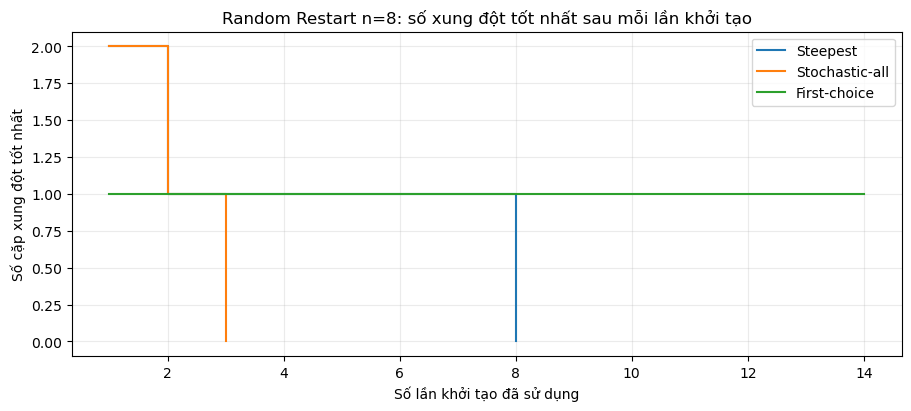

In [7]:
example_starts=np.random.default_rng(71).integers(0,8,size=(100,8))
for name,method in [('Steepest',hill_climb_steepest),('Stochastic-all',hill_climb_stochastic_all),('First-choice',hill_climb_first_choice)]:
    r=hill_climbing_random_restart(method,8,seed=2026,initial_boards=example_starts)
    print(f'{name:16s} f={r["best_f"]}, starts={r["starts"]}, '
          f'restarts={r["restarts_used"]}, evals={r["objective_evaluations"]}, '
          f'lý do={r["stop_reason"]}')
# Đường best-so-far theo lần chạy lại (mỗi điểm tương ứng một khởi tạo mới).
fig,ax=plt.subplots(figsize=(9,4),constrained_layout=True)
for name,method in [('Steepest',hill_climb_steepest),('Stochastic-all',hill_climb_stochastic_all),('First-choice',hill_climb_first_choice)]:
    r=hill_climbing_random_restart(method,8,seed=2026,initial_boards=example_starts)
    ax.step(range(1,r['starts']+1),r['best_history'],where='post',label=name)
ax.set_title('Random Restart n=8: số xung đột tốt nhất sau mỗi lần khởi tạo')
ax.set_xlabel('Số lần khởi tạo đã sử dụng')
ax.set_ylabel('Số cặp xung đột tốt nhất')
ax.yaxis.set_major_locator(MaxNLocator(integer=True)) if 'MaxNLocator' in globals() else None
ax.grid(alpha=.25);ax.legend()
plt.show()

## 3. Task 5 — Simulated Annealing (SA)

Chọn một láng giềng ngẫu nhiên `x'` và đặt `Δ = conflicts(x') - conflicts(x)`:

- `Δ ≤ 0`: nhận bước cải thiện **hoặc bằng nhau**.
- `Δ > 0`: nhận với xác suất `exp(-Δ/T(t))`, khi `T(t) > 0`.
- Luôn ghi lại `current_history` (có thể tăng) và `best_history` (không tăng), do SA có thể tạm đi xa nghiệm tốt nhất.

Lịch nhiệt dùng `t=1,2,...` theo đúng biểu thức của PDF: mũ `T0 α^t`, tuyến tính `T0 - ηt`, fast `T0/(1+t)`, logarithmic `T0/ln(1+t)` (chỉ gọi với `t>0`). Khi `T≤0`, dừng trước khi thử bước mới. `T0` là tham số trong công thức, vì vậy `T(1)` của các lịch có thể khác `T0`.

In [8]:
def temperature_exponential(t, T0, alpha):
    """T(t)=T0 * alpha**t, t>=1, 0<alpha<1."""
    return float(T0 * alpha**t)

def temperature_linear(t, T0, eta):
    """T(t)=T0 - eta*t, có thể trở thành không dương."""
    return float(T0 - eta*t)

def temperature_fast(t, T0):
    return float(T0 / (1 + t))

def temperature_logarithmic(t, T0):
    return float(T0 / math.log1p(t))

def simulated_annealing(initial_board, schedule, seed=0, max_steps=2999,
                        total_evaluation_budget=3000):
    """Task 5: SA thuần Python/Numpy do Tri tự cài đặt.

    Không import n_queens_sa.py hay bất kỳ module thuật toán nào của người khác.
    Mỗi bước chọn đều một láng giềng bằng cách dời 1 hậu sang hàng khác
    cùng cột. Δ<=0 nhận chắc chắn; Δ>0 nhận với xác suất exp(-Δ/T).
    Luôn giữ bản sao nghiệm tốt nhất, không chỉ nghiệm hiện tại.
    """
    board = check_board(initial_board)
    if not callable(schedule) or max_steps < 1 or total_evaluation_budget < 1:
        raise ValueError('schedule phải gọi được và ngân sách phải dương.')
    rng = np.random.default_rng(seed)
    current_f = int(conflicts(board))
    initial_f = current_f
    best_board, best_f = board.copy(), current_f
    current_history, best_history = [current_f], [best_f]
    worse_proposed = worse_accepted = plateau_accepted = 0
    steps = 0
    reason = 'step_budget'
    for t in range(1, max_steps + 1):
        if best_f == 0:
            reason = 'solved'
            break
        if steps + 1 >= total_evaluation_budget:
            reason = 'evaluation_budget'
            break
        temperature = float(schedule(t))
        if not math.isfinite(temperature):
            raise ValueError('T(t) không được vô hạn hoặc NaN.')
        if temperature <= 0:
            reason = 'cooled'
            break
        candidate = random_neighbor(board, rng)
        candidate_f = int(conflicts(candidate))
        delta = candidate_f - current_f
        if delta > 0:
            worse_proposed += 1
            # Test log(rng) thay vì tính exp giúp ổn định với T rất nhỏ.
            accepted = math.log(max(float(rng.random()), np.finfo(float).tiny)) < -delta / temperature
            worse_accepted += int(accepted)
        else:
            accepted = True
            plateau_accepted += int(delta == 0)
        if accepted:
            board, current_f = candidate, candidate_f
            if current_f < best_f:
                best_board, best_f = board.copy(), current_f
        steps += 1
        current_history.append(int(current_f))
        best_history.append(int(best_f))
    if best_f == 0:
        reason = 'solved'
    return {
        'algorithm': 'Simulated Annealing',
        'board': best_board.copy(), 'conflicts': int(best_f),
        'best_board': best_board.copy(), 'best_f': int(best_f),
        'current_board': board.copy(), 'final_f': int(current_f),
        'initial_f': int(initial_f), 'success': best_f == 0,
        'steps': steps, 'iterations': steps,
        'candidate_evaluations': steps, 'objective_evaluations': steps + 1,
        'stop_reason': reason, 'current_history': current_history,
        'best_history': best_history, 'history': best_history,
        'worse_proposed': worse_proposed, 'worse_accepted': worse_accepted,
        'plateau_accepted': plateau_accepted,
    }

Mũ          : f đầu=28 / f tốt nhất=0, các bước=881, nhận bước xấu=95/639
Tuyến tính  : f đầu=28 / f tốt nhất=0, các bước=2809, nhận bước xấu=676/1556
Fast        : f đầu=28 / f tốt nhất=0, các bước=183, nhận bước xấu=1/141


Logarithmic : f đầu=28 / f tốt nhất=1, các bước=2999, nhận bước xấu=267/2137


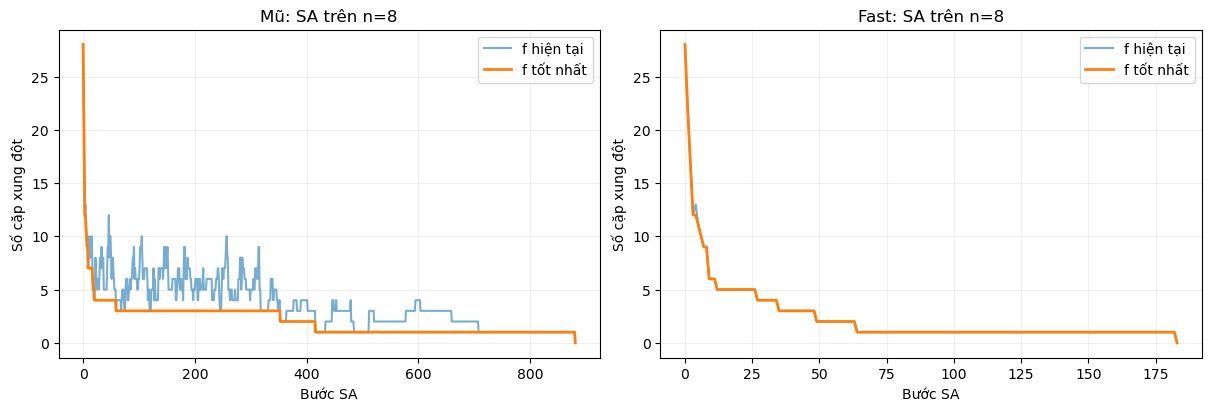

In [9]:
test_board=np.array([0,0,0,0,0,0,0,0])
for schedule_name,schedule in [('Mũ',lambda t:temperature_exponential(t,5,.995)),
                               ('Tuyến tính',lambda t:temperature_linear(t,5,5/3001)),
                               ('Fast',lambda t:temperature_fast(t,5)),
                               ('Logarithmic',lambda t:temperature_logarithmic(t,5))]:
    r=simulated_annealing(test_board,schedule,seed=2026)
    print(f'{schedule_name:12s}: f đầu={r["initial_f"]} / f tốt nhất={r["best_f"]}, '
          f'các bước={r["steps"]}, nhận bước xấu={r["worse_accepted"]}/{r["worse_proposed"]}')
fig,axes=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
for i,(name,schedule) in enumerate([('Mũ',lambda t:temperature_exponential(t,5,.995)),
                                   ('Fast',lambda t:temperature_fast(t,5))]):
    r=simulated_annealing(test_board,schedule,seed=2026)
    axes[i].plot(r['current_history'],label='f hiện tại',alpha=.6)
    axes[i].plot(r['best_history'],label='f tốt nhất',linewidth=2)
    axes[i].set_title(f'{name}: SA trên n=8')
    axes[i].set_xlabel('Bước SA');axes[i].set_ylabel('Số cặp xung đột')
    axes[i].grid(alpha=.2);axes[i].legend()
plt.show()

## 4. Kiểm chứng tính đúng trước thực nghiệm

Kiểm tra bằng một **oracle độc lập** (duyệt các cặp hậu) để tránh tự kiểm bằng cùng công thức lỗi. Vét cạn toàn bộ `4^4=256` trạng thái cho `conflicts()`. Thử 40 bàn cờ trên từng n=4,8 với cả Restart và SA; kiểm tra trạng thái không bị sửa, khả năng tái lập seed, mọi nghiệm tốt nhất, ngân sách, độ dài lịch sử và tính đơn điệu của nghiệm tốt nhất. Một lần SA **không bắt buộc thành công** và không được tự nhận có bảo đảm tìm toàn cục.

In [10]:
# Oracle độc lập: đếm chính xác mọi cặp hậu, không dùng cách đếm theo nhóm.
def conflicts_oracle(board):
    return sum(bool(board[i] == board[j] or abs(int(board[i])-int(board[j])) == j-i)
               for i in range(len(board)) for j in range(i+1, len(board)))

from itertools import product
for values in product(range(4), repeat=4):
    assert int(conflicts(values)) == conflicts_oracle(values)
assert int(conflicts([1, 3, 0, 2])) == 0
rng_test = np.random.default_rng(91025)
for n in (4, 8):
    for _ in range(40):
        board = rng_test.integers(0, n, n)
        original = board.copy()
        for fn in (hill_climb_steepest, hill_climb_stochastic_all, hill_climb_first_choice):
            outcome = fn(board, seed=19)
            assert outcome['conflicts'] == conflicts_oracle(outcome['board'])
            assert np.array_equal(board, original)
        fixed_starts = [rng_test.integers(0, n, n) for j in range(100)]
        for fn in (hill_climb_steepest, hill_climb_stochastic_all, hill_climb_first_choice):
            run = hill_climbing_random_restart(fn, n, seed=33, max_starts=100,
                    total_evaluation_budget=500, initial_boards=fixed_starts)
            assert run['best_f'] == conflicts_oracle(run['best_board'])
            assert run['starts'] <= 100 and run['objective_evaluations'] <= 500
            assert run['restarts_used'] == run['starts'] - 1
            assert run['best_f'] == min(x['final_f'] for x in run['attempts'])
            assert all(x['best_so_far'] >= y['best_so_far'] for x,y in zip(run['attempts'],run['attempts'][1:]))
        schedule_test = lambda t: temperature_exponential(t, 5.0, 0.995)
        r1 = simulated_annealing(board, schedule_test, seed=19, max_steps=400, total_evaluation_budget=401)
        r2 = simulated_annealing(board, schedule_test, seed=19, max_steps=400, total_evaluation_budget=401)
        assert np.array_equal(r1['best_board'], r2['best_board'])
        assert r1['current_history'] == r2['current_history']
        assert np.array_equal(board, original)
        assert r1['best_f'] == conflicts_oracle(r1['best_board'])
        assert r1['final_f'] == conflicts_oracle(r1['current_board'])
        assert r1['best_f'] == min(r1['current_history'])
        assert len(r1['best_history']) == len(r1['current_history']) == r1['steps']+1
        assert all(a >= b for a,b in zip(r1['best_history'],r1['best_history'][1:]))
        assert r1['objective_evaluations'] <= 401
        assert 0 <= r1['worse_accepted'] <= r1['worse_proposed']
assert simulated_annealing([1,3,0,2],lambda t:2.0)['steps'] == 0
assert hill_climbing_random_restart(hill_climb_steepest,4,
    initial_boards=[np.array([1,3,0,2])]*100)['starts'] == 1
assert hill_climbing_random_restart(hill_climb_steepest,4, total_evaluation_budget=1)['objective_evaluations'] == 1
for invalid in ([4,0,0,0], [-1,0,0,0]):
    try:
        check_board(invalid)
        raise AssertionError('check_board phải từ chối board không hợp lệ')
    except ValueError:
        pass
print('PASS — oracle, n=4 exhaustive, kiểm thử n=4/8, restart, SA, seed, ngân sách và tính không sửa input')

PASS — oracle, n=4 exhaustive, kiểm thử n=4/8, restart, SA, seed, ngân sách và tính không sửa input


## 5. Thực nghiệm chính — Random Restart so với SA

- **Cấu hình:** `n ∈ {4,8}`, **40 lượt chạy/cấu hình**, cùng dãy 100 bàn cờ khởi tạo cho ba biến thể Restart; SA xuất phát tại phần tử đầu của cùng dãy đó.
- **Ngân sách tương đối công bằng:** tối đa **3.000 lần gọi `conflicts()` cho toàn bộ một lượt thử**, bao gồm cả chi phí khởi tạo lại. Random Restart tối đa 100 lần khởi tạo; SA tối đa 2.999 bước, và dừng sớm khi `f=0`. Chỉ số `mean_evaluations` cho biết phần ngân sách đã sử dụng thực tế.
- **SA chính:** lịch mũ `T0=5`, `α=.995`. Hạt giống cố định và thứ tự chạy luân phiên. Thời gian `perf_counter()` chỉ bao quanh lời gọi thuật toán, không gồm sinh dữ liệu/hình/bảng.
- **Thận trọng khi so sánh:** cùng giới hạn đánh giá không làm các phương pháp có **cùng lượng công việc thực tế**, đặc biệt khi dừng sớm. Xem đồng thời tỉ lệ thành công, chất lượng nghiệm, số đánh giá, số khởi tạo và thời gian.

In [11]:
import pandas as pd
from IPython.display import display

BENCH_TRIALS = 40
MAX_STARTS = 100
FAIR_EVAL_BUDGET = 3000
MAX_SA_STEPS = FAIR_EVAL_BUDGET - 1
restart_methods = {
    'Restart Steepest': hill_climb_steepest,
    'Restart Stochastic-all': hill_climb_stochastic_all,
    'Restart First-choice': hill_climb_first_choice,
}
sa_schedule = lambda t: temperature_exponential(t, T0=5.0, alpha=0.995)
main_records = []
main_examples = {}
main_raw = {}
from time import perf_counter
for n in (4, 8):
    for trial in range(BENCH_TRIALS):
        # Đồng bộ bộ khởi tạo giữa 3 biến thể Restart; SA nhận cùng board đầu.
        seed = 20261016 + 1000*n + trial
        starts = np.random.default_rng(seed).integers(0, n, size=(MAX_STARTS, n))
        algorithm_seed = 90000 + 1000*n + trial
        jobs = list(restart_methods.items()) + [('SA - Exponential', None)]
        jobs = jobs[trial % len(jobs):] + jobs[:trial % len(jobs)]
        for name, fn in jobs:
            timer = perf_counter()
            if fn is None:
                out = simulated_annealing(starts[0], sa_schedule, seed=algorithm_seed,
                    max_steps=MAX_SA_STEPS, total_evaluation_budget=FAIR_EVAL_BUDGET)
                starts_count = 1
            else:
                out = hill_climbing_random_restart(fn, n, seed=algorithm_seed,
                    max_starts=MAX_STARTS, total_evaluation_budget=FAIR_EVAL_BUDGET,
                    initial_boards=starts)
                starts_count = out['starts']
            elapsed_ms = (perf_counter() - timer) * 1000
            assert out['objective_evaluations'] <= FAIR_EVAL_BUDGET
            assert out['conflicts'] == conflicts_oracle(out['board'])
            main_records.append({
                'n': n, 'trial': trial, 'algorithm': name, 'initial_f': int(conflicts(starts[0])),
                'best_f': out['conflicts'], 'success': int(out['success']),
                'starts': starts_count, 'iterations': out['iterations'],
                'objective_evaluations': out['objective_evaluations'],
                'runtime_ms': elapsed_ms, 'stop_reason': out['stop_reason'],
            })
            main_raw[(n,trial,name)] = out
main_df = pd.DataFrame(main_records)
main_summary = (main_df.groupby(['n','algorithm'], sort=False)
    .agg(trials=('success','size'), success_rate=('success','mean'),
         mean_best_f=('best_f','mean'), median_best_f=('best_f','median'),
         mean_starts=('starts','mean'), mean_iterations=('iterations','mean'),
         mean_evaluations=('objective_evaluations','mean'),
         median_evaluations=('objective_evaluations','median'),
         mean_runtime_ms=('runtime_ms','mean'), median_runtime_ms=('runtime_ms','median')))
print('BẢNG 1 — Mỗi cấu hình có 40 lượt độc lập; tối đa 100 khởi tạo / 3.000 evaluations')
display(main_summary.round(3))
print('LÝ DO DỪNG (không đánh đồng hết ngân sách với local optimum)')
display(pd.crosstab([main_df.n,main_df.algorithm], main_df.stop_reason))
assert len(main_df) == 2*4*BENCH_TRIALS

BẢNG 1 — Mỗi cấu hình có 40 lượt độc lập; tối đa 100 khởi tạo / 3.000 evaluations


trials  success_rate  mean_best_f  median_best_f  \
n algorithm                                                                  
4 Restart Steepest            40         1.000        0.000            0.0   
  Restart Stochastic-all      40         1.000        0.000            0.0   
  Restart First-choice        40         1.000        0.000            0.0   
  SA - Exponential            40         1.000        0.000            0.0   
8 Restart Steepest            40         0.875        0.125            0.0   
  Restart Stochastic-all      40         0.700        0.300            0.0   
  Restart First-choice        40         0.750        0.250            0.0   
  SA - Exponential            40         0.975        0.025            0.0   

                          mean_starts  mean_iterations  mean_evaluations  \
n algorithm                                                                
4 Restart Steepest              2.500            3.925            67.600   
  Restart Stochastic-all        3.550            6.500           112.150   
  Restart First-choice          3.175            5.975           113.575   
  SA - Exponential              1.000           92.775            93.775   
8 Restart Steepest              7.575           16.750          1184.975   
  Restart Stochastic-all       12.250           25.875          1714.650   
  Restart First-choice          8.525           40.950          1725.775   
  SA - Exponential              1.000          943.875           944.875   

                          median_evaluations  mean_runtime_ms  \
n algorithm                                                     
4 Restart Steepest                      50.0            3.600   
  Restart Stochastic-all               105.0            4.591   
  Restart First-choice                 100.5            6.502   
  SA - Exponential                      64.0            3.724   
8 Restart Steepest                     956.5           29.822   
  Restart Stochastic-all              1432.5           43.182   
  Restart First-choice                1748.0           75.482   
  SA - Exponential                     712.5           52.877   

                          median_runtime_ms  
n algorithm                                  
4 Restart Steepest                    3.513  
  Restart Stochastic-all              4.604  
  Restart First-choice                4.664  
  SA - Exponential                    2.582  
8 Restart Steepest                   24.163  
  Restart Stochastic-all             36.730  
  Restart First-choice               76.602  
  SA - Exponential                   39.466

LÝ DO DỪNG (không đánh đồng hết ngân sách với local optimum)


stop_reason               evaluation_budget  solved  step_budget
n algorithm                                                     
4 Restart First-choice                    0      40            0
  Restart Steepest                        0      40            0
  Restart Stochastic-all                  0      40            0
  SA - Exponential                        0      40            0
8 Restart First-choice                   10      30            0
  Restart Steepest                        5      35            0
  Restart Stochastic-all                 12      28            0
  SA - Exponential                        0      39            1

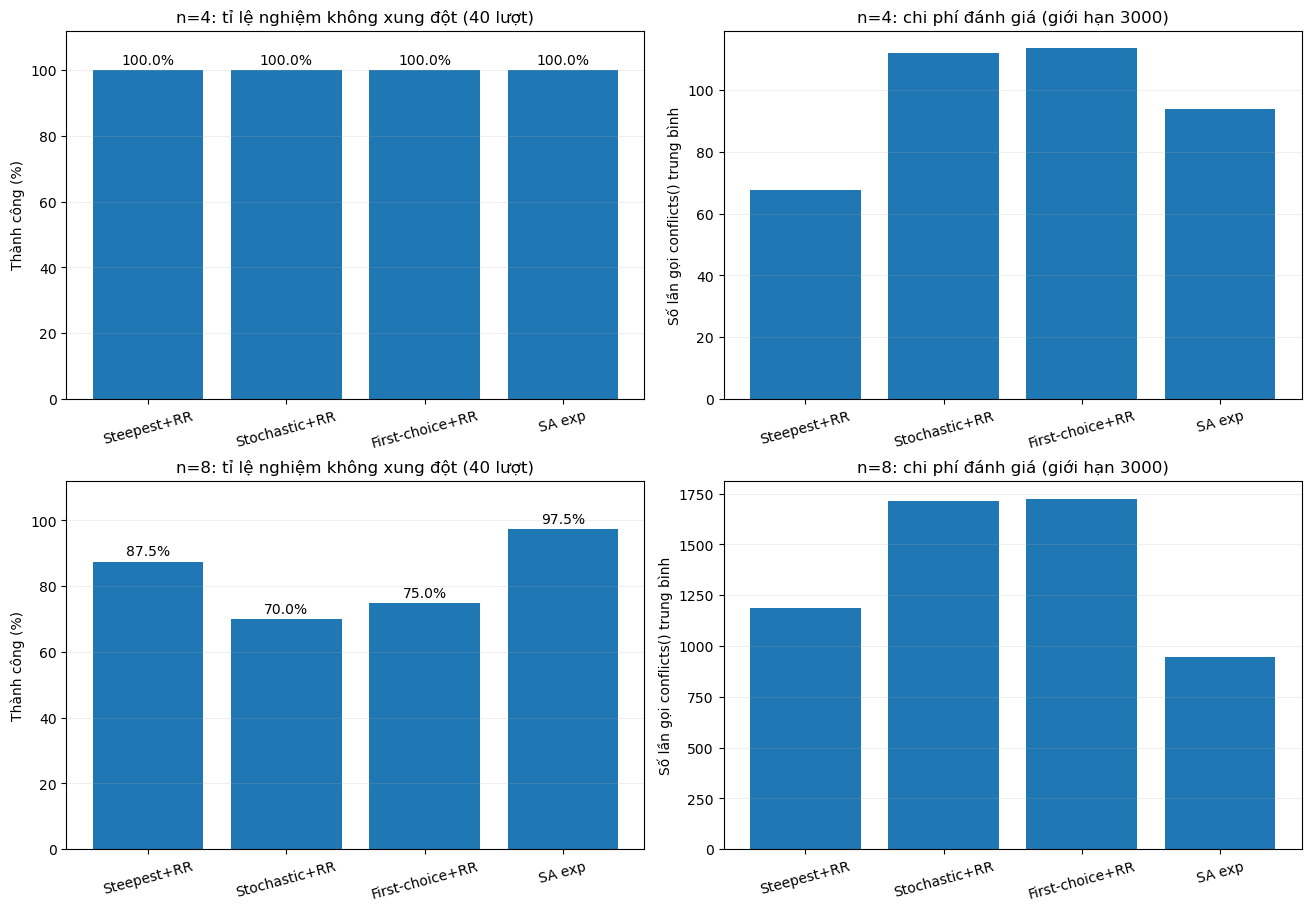

In [12]:
from matplotlib.ticker import MaxNLocator
fig, axes = plt.subplots(2, 2, figsize=(13, 9), constrained_layout=True)
for i,n in enumerate((4,8)):
    summary=main_summary.loc[n]
    labels=summary.index.to_list()
    success=100*summary['success_rate'].to_numpy()
    a=axes[i,0]
    bars=a.bar(range(len(labels)),success)
    a.bar_label(bars,labels=[f'{x:.1f}%' for x in success],padding=2)
    a.set_xticks(range(len(labels)),['Steepest+RR','Stochastic+RR','First-choice+RR','SA exp'],rotation=15)
    a.set_ylim(0,112)
    a.set_ylabel('Thành công (%)')
    a.set_title(f'n={n}: tỉ lệ nghiệm không xung đột ({BENCH_TRIALS} lượt)')
    a.grid(axis='y',alpha=.2)
    a=axes[i,1]
    a.bar(range(len(labels)),summary['mean_evaluations'])
    a.set_xticks(range(len(labels)),['Steepest+RR','Stochastic+RR','First-choice+RR','SA exp'],rotation=15)
    a.set_ylabel('Số lần gọi conflicts() trung bình')
    a.set_title(f'n={n}: chi phí đánh giá (giới hạn {FAIR_EVAL_BUDGET})')
    a.grid(axis='y',alpha=.2)
plt.show()

## 6. Khảo sát ảnh hưởng `T0` và tốc độ nguội

Thí nghiệm nhân tố **2 × 2** với `T0 ∈ {2,8}`, `α ∈ {0.98,0.995}` cho lịch mũ. Thêm hai lịch khác **Linear** (`T0=5`, `η=5/3001`) và **Fast** (`T0=5`). Với mỗi `n=4,8`, chạy **30 seed/cấu hình** và cùng bàn cờ khởi tạo/seed giữa sáu lịch. So sánh giá trị `best_f`, tỉ lệ đạt `f=0`, số bước, thời gian và tỉ lệ nhận nước đi xấu thực đo.

Lưu ý: lịch có nhiệt độ cao trong thời gian dài có thể khám phá tốt nhưng **không được suy ra luôn cho kết quả tốt nhất**. Khảo sát này không thay thế toàn bộ nghiên cứu lịch nhiệt ở Bài 5.

In [13]:
# Thiết kế thí nghiệm nhân tố 2x2 (T0 x alpha) + hai lịch nhiệt khác.
# Bài 4 tự triển khai SA, không phụ thuộc notebook Bài 5 của nhóm.
SA_TRIALS = 30
schedules = {
    'Exp T0=2 α=.98': lambda t: temperature_exponential(t,2.0,.98),
    'Exp T0=2 α=.995': lambda t: temperature_exponential(t,2.0,.995),
    'Exp T0=8 α=.98': lambda t: temperature_exponential(t,8.0,.98),
    'Exp T0=8 α=.995': lambda t: temperature_exponential(t,8.0,.995),
    'Linear T0=5': lambda t: temperature_linear(t,5.0,5.0/(MAX_SA_STEPS+2)),
    'Fast T0=5': lambda t: temperature_fast(t,5.0),
}
sa_records=[]
sa_histories={}
for n in (4,8):
    for trial in range(SA_TRIALS):
        board_seed=177000+1000*n+trial
        algo_seed=288000+1000*n+trial
        start=np.random.default_rng(board_seed).integers(0,n,size=n)
        names=list(schedules)
        names=names[trial%len(names):]+names[:trial%len(names)]
        for name in names:
            tic=perf_counter()
            r=simulated_annealing(start, schedules[name], seed=algo_seed,
                max_steps=MAX_SA_STEPS,total_evaluation_budget=FAIR_EVAL_BUDGET)
            elapsed_ms=(perf_counter()-tic)*1000
            assert r['best_f'] == conflicts_oracle(r['best_board'])
            sa_records.append({
                'n':n,'trial':trial,'schedule':name,'initial_f':int(conflicts(start)),
                'best_f':r['best_f'],'final_f':r['final_f'], 'success':int(r['success']),
                'steps':r['steps'],'objective_evaluations':r['objective_evaluations'],
                'worse_proposed':r['worse_proposed'],'worse_accepted':r['worse_accepted'],
                'runtime_ms':elapsed_ms,'stop_reason':r['stop_reason'],
            })
            sa_histories[(n,trial,name)]=r['best_history']
sa_df=pd.DataFrame(sa_records)
sa_summary=(sa_df.groupby(['n','schedule'],sort=False)
    .agg(trials=('success','size'),success_rate=('success','mean'),
         mean_best_f=('best_f','mean'),mean_steps=('steps','mean'),
         mean_evaluations=('objective_evaluations','mean'),
         worse_proposed=('worse_proposed','sum'),worse_accepted=('worse_accepted','sum'),
         median_ms=('runtime_ms','median')))
sa_summary['worse_accept_rate']=sa_summary.worse_accepted / sa_summary.worse_proposed.replace({0:np.nan})
print('BẢNG 2 — 30 lượt cho mỗi lịch và từng n; cùng board/seed giữa các lịch')
display(sa_summary.round(3))
assert len(sa_df) == 2*SA_TRIALS*len(schedules)

BẢNG 2 — 30 lượt cho mỗi lịch và từng n; cùng board/seed giữa các lịch


trials  success_rate  mean_best_f  mean_steps  \
n schedule                                                         
4 Exp T0=2 α=.98       30         1.000        0.000      54.767   
  Exp T0=2 α=.995      30         1.000        0.000      77.000   
  Exp T0=8 α=.98       30         1.000        0.000      79.500   
  Exp T0=8 α=.995      30         1.000        0.000      88.767   
  Linear T0=5          30         1.000        0.000     105.100   
  Fast T0=5            30         1.000        0.000      43.200   
8 Exp T0=2 α=.98       30         0.900        0.100    1007.767   
  Exp T0=2 α=.995      30         1.000        0.000     758.767   
  Exp T0=8 α=.98       30         1.000        0.000     616.300   
  Exp T0=8 α=.995      30         0.967        0.033    1121.000   
  Linear T0=5          30         0.433        0.600    2693.467   
  Fast T0=5            30         0.933        0.067     836.800   

                   mean_evaluations  worse_proposed  worse_accepted  \
n schedule                                                            
4 Exp T0=2 α=.98             55.767             987             182   
  Exp T0=2 α=.995            78.000            1238             381   
  Exp T0=8 α=.98             80.500            1193             509   
  Exp T0=8 α=.995            89.767            1068             776   
  Linear T0=5               106.100            1267             931   
  Fast T0=5                  44.200             936              26   
8 Exp T0=2 α=.98           1008.767           27717             256   
  Exp T0=2 α=.995           759.767           18576            1156   
  Exp T0=8 α=.98            617.300           15474             874   
  Exp T0=8 α=.995          1122.000           25057            3633   
  Linear T0=5              2694.467           44643           18753   
  Fast T0=5                 837.800           23238              26   

                   median_ms  worse_accept_rate  
n schedule                                       
4 Exp T0=2 α=.98       1.799              0.184  
  Exp T0=2 α=.995      2.594              0.308  
  Exp T0=8 α=.98       3.085              0.427  
  Exp T0=8 α=.995      2.808              0.727  
  Linear T0=5          2.558              0.735  
  Fast T0=5            2.063              0.028  
8 Exp T0=2 α=.98      30.048              0.009  
  Exp T0=2 α=.995     30.233              0.062  
  Exp T0=8 α=.98      34.765              0.056  
  Exp T0=8 α=.995     56.247              0.145  
  Linear T0=5        147.176              0.420  
  Fast T0=5           42.365              0.001

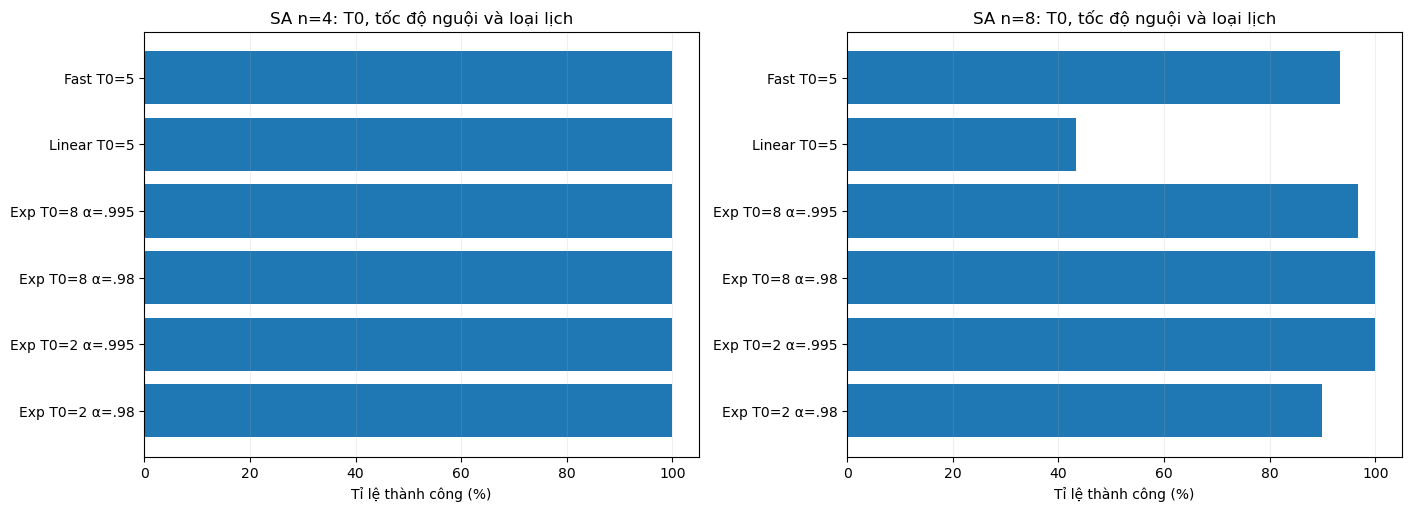

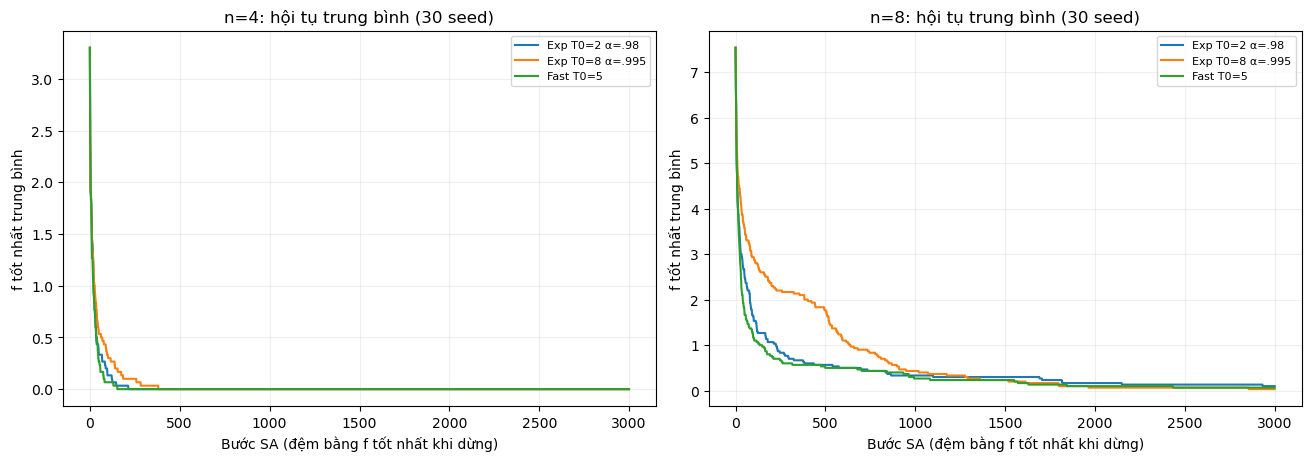

In [14]:
fig, axes=plt.subplots(1,2,figsize=(14,5),constrained_layout=True)
for ax,n in zip(axes,(4,8)):
    table=sa_summary.loc[n]
    labels=table.index.tolist()
    ax.barh(range(len(labels)),100*table.success_rate)
    ax.set_yticks(range(len(labels)),labels)
    ax.set_xlim(0,105)
    ax.set_xlabel('Tỉ lệ thành công (%)')
    ax.set_title(f'SA n={n}: T0, tốc độ nguội và loại lịch')
    ax.grid(axis='x',alpha=.2)
plt.show()
# Các chuỗi là f tốt nhất, không phải chỉ số trạng thái hiện tại.
fig,axes=plt.subplots(1,2,figsize=(13,4.5),constrained_layout=True)
for ax,n in zip(axes,(4,8)):
    for name in ('Exp T0=2 α=.98','Exp T0=8 α=.995','Fast T0=5'):
        histories=[sa_histories[n,trial,name] for trial in range(SA_TRIALS)]
        arr=np.stack([np.pad(h,(0,FAIR_EVAL_BUDGET-len(h)),mode='edge') for h in histories])
        ax.plot(np.mean(arr,axis=0),label=name)
    ax.set_title(f'n={n}: hội tụ trung bình ({SA_TRIALS} seed)')
    ax.set_xlabel('Bước SA (đệm bằng f tốt nhất khi dừng)')
    ax.set_ylabel('f tốt nhất trung bình')
    ax.grid(alpha=.2)
    ax.legend(fontsize=8)
plt.show()

## 7. Nhận xét dựa trên các số liệu thực đo

Nhận xét dưới đây được **tạo từ bảng dữ liệu phía trên**, nhằm tránh trích số liệu cũ khi chạy lại với máy khác. Khi gặp tỷ lệ bằng nhau, kết quả ghi nhận là *đồng hạng* chứ không tự tạo người thắng.

**Diễn giải:** Random Restart thử nhiều vùng của không gian tìm kiếm, có thể khắc phục bẫy cục bộ của từng lần HC. SA chấp nhận bước xấu phụ thuộc nhiệt độ nên có cơ hội thoát bẫy mà không cần khởi động lại; đổi lại không đảm bảo hội tụ toàn cục trong ngân sách hữu hạn. Nên phân biệt `final_f` (trạng thái SA tại cuối chạy) với `best_f` (nghiệm tốt nhất đã thấy).

In [15]:
from IPython.display import Markdown
paragraphs=[]
for n in (4,8):
    part=main_summary.loc[n]
    ranks=part.sort_values('success_rate',ascending=False)
    best_rate=float(ranks.success_rate.iloc[0])
    leaders=ranks.index[ranks.success_rate==best_rate].tolist()
    paragraphs.append(
        f'- **n={n}** — tỷ lệ thành công cao nhất ở bảng chính: '
        f'**{100*best_rate:.1f}%**, đạt bởi **{", ".join(leaders)}** '
        f'({BENCH_TRIALS} lần). Số phép đánh giá trung bình thấp nhất: '
        f'**{part.mean_evaluations.idxmin()}** ({part.mean_evaluations.min():.1f} lần). '
        'Hai tiêu chí là khác nhau; không suy ra phương pháp tối ưu tuyệt đối.'
    )
    table=sa_summary.loc[n]
    top=table.success_rate.max()
    leaders2=table.index[table.success_rate==top].tolist()
    paragraphs.append(f'  - Khảo sát lịch nhiệt n={n}: tỷ lệ cao nhất **{100*top:.1f}%** '
                      f'ở **{", ".join(leaders2)}**. '
                      'Các chênh lệch nhỏ cần được kiểm tra với nhiều seed hơn.')
paragraphs.append('- **Giới hạn:** Đây là thống kê trên 40 hoặc 30 seed/cấu hình, với trần '
    f'{FAIR_EVAL_BUDGET} đánh giá và chỉ n=4,8; chưa suy ra một phương pháp tốt nhất cho mọi n. '
    'Thời gian phụ thuộc môi trường; thời gian tạo dữ liệu và vẽ hình không nằm trong phép đo thuật toán.')
display(Markdown('\n'.join(paragraphs)))

- **n=4** — tỷ lệ thành công cao nhất ở bảng chính: **100.0%**, đạt bởi **Restart Steepest, Restart Stochastic-all, Restart First-choice, SA - Exponential** (40 lần). Số phép đánh giá trung bình thấp nhất: **Restart Steepest** (67.6 lần). Hai tiêu chí là khác nhau; không suy ra phương pháp tối ưu tuyệt đối.
  - Khảo sát lịch nhiệt n=4: tỷ lệ cao nhất **100.0%** ở **Exp T0=2 α=.98, Exp T0=2 α=.995, Exp T0=8 α=.98, Exp T0=8 α=.995, Linear T0=5, Fast T0=5**. Các chênh lệch nhỏ cần được kiểm tra với nhiều seed hơn.
- **n=8** — tỷ lệ thành công cao nhất ở bảng chính: **97.5%**, đạt bởi **SA - Exponential** (40 lần). Số phép đánh giá trung bình thấp nhất: **SA - Exponential** (944.9 lần). Hai tiêu chí là khác nhau; không suy ra phương pháp tối ưu tuyệt đối.
  - Khảo sát lịch nhiệt n=8: tỷ lệ cao nhất **100.0%** ở **Exp T0=2 α=.995, Exp T0=8 α=.98**. Các chênh lệch nhỏ cần được kiểm tra với nhiều seed hơn.
- **Giới hạn:** Đây là thống kê trên 40 hoặc 30 seed/cấu hình, với trần 3000 đánh giá và chỉ n=4,8; chưa suy ra một phương pháp tốt nhất cho mọi n. Thời gian phụ thuộc môi trường; thời gian tạo dữ liệu và vẽ hình không nằm trong phép đo thuật toán.

## 8. Dữ liệu thô và cách chạy lại

Lưu dữ liệu **thực đo** vào thư mục tương đối `ket_qua_bai4/` để ghép báo cáo tổng sau này. Không phụ thuộc thư mục cá nhân hay file GitHub bên ngoài; notebook này chạy độc lập nếu đã cài `numpy`, `matplotlib`, `pandas`, `ipython`. Không tạo báo cáo Word/PDF riêng theo thống nhất nhóm.

In [16]:
from pathlib import Path
output_dir=Path('ket_qua_bai4')
output_dir.mkdir(exist_ok=True)
main_df.to_csv(output_dir/'bai4_so_sanh_restart_sa.csv',index=False,encoding='utf-8-sig')
sa_df.to_csv(output_dir/'bai4_khao_sat_lich_nhiet.csv',index=False,encoding='utf-8-sig')
main_summary.to_csv(output_dir/'bai4_tong_hop.csv',encoding='utf-8-sig')
sa_summary.to_csv(output_dir/'bai4_tong_hop_lich_nhiet.csv',encoding='utf-8-sig')
print('Đã lưu dữ liệu thực nghiệm trong:',output_dir.resolve())

Đã lưu dữ liệu thực nghiệm trong: D:\SGU\CNTT\TTNTNC\sgu-team-2026-advanced-ai-subject\weekly assignments\lab03 - local search\notebooks_theo_bai\ket_qua_bai4


### Kết luận Bài 4

1. Task 4: triển khai Random Restart cho **cả ba thuật toán** Hill Climbing, giới hạn tối đa 100 lần khởi tạo và lưu nghiệm tốt nhất, tổng số restart, chi phí.
2. Task 5: triển khai SA **tự viết**, chấp nhận bước xấu theo xác suất nhiệt độ, ghi lịch sử hiện tại và tốt nhất, có animation tĩnh bằng biểu đồ hội tụ.
3. Thực nghiệm **n=4 và n=8**, có các bảng và hình, nhiều seed, thời gian và số lần gọi hàm mục tiêu, kiểm chứng độc lập.
4. Không có kết luận hiệu năng vượt quá dữ liệu trong các cấu hình/seed cụ thể. Mọi thuật toán được cài đặt độc lập trong notebook.